# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви - аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі -
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` - результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Голейчук Ілля'
LIST_NUMBER  = 2

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = 'Львів, Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 2: Львів, Україна


In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.0.1


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** - `osmnx` питає Overpass API просто зараз;
* **знімок** - ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче - живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass - безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов -
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_львів


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності - кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму - надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію - навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки - latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'


> Якщо жодна машина не відповіла - виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є - прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено - читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    t0, b0 = time.time(), cache_bytes()
    raw = getter()
    g = clean(raw)
    g.to_parquet(path, index=False)
    g = gpd.read_parquet(path)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    return g

In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 148.4 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 3668 | ребер 8627


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` - нуль.

In [9]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.028,0.209
heritage,знімок,148,0.0,0.254,0.306
stations,знімок,8,0.0,0.204,0.211
amenities,знімок,1526,0.0,0.324,0.215
мережа walk,знімок,12295,0.0,1.097,0.22


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` - `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` - `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці -
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
mask = heritage['historic'].notna() | heritage['tourism'].isin(TOURISM_OK)
cand = heritage[mask & heritage['name'].notna()].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', len(cand))

усього у шарі heritage : 148
підходять за тегами    : 109
з них мають name       : 95


In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
house       18
yes         18
church       6
building     4
tomb         4
ruins        3
tower        2
memorial     2
castle       2
monument     2

=== tourism ===
tourism
museum        22
attraction     8
artwork        1

типи геометрії: {'Polygon': 95}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони - ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15-20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття - хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами - перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір - **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [12]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

wiki_cols = [c for c in ['wikidata', 'wikipedia', 'wikipedia:uk', 'wikipedia:en', 'wikipedia:pl'] if c in cand.columns]
cand['wiki'] = cand[wiki_cols].notna().any(axis=1).astype(int)
lang_cols = [c for c in cand.columns if c.startswith('name:')]
cand['n_lang'] = cand[lang_cols].notna().sum(axis=1)
cand['is_museum'] = cand['tourism'].isin(['museum', 'gallery']).astype(int)
cand['has_historic'] = cand['historic'].notna().astype(int)

cand['score'] = (
    0.35 * cand['wiki'].rank(pct=True) +
    0.30 * cand['n_lang'].rank(pct=True) +
    0.20 * cand['is_museum'].rank(pct=True) +
    0.10 * cand['has_historic'].rank(pct=True) +
    0.05 * cand['area_m2'].rank(pct=True)
)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))

кандидатів   : 95
мають wiki   : 29


### Завдання 3.2 - обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм - площею будівлі -
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні - поясніть у звіті, що це
означає для слова «найкращі».

In [13]:
N_SMALL, N_LARGE = 10, 30

top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
overlap   = len(set(top10['name']) & set(top_naive['name']))
print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                      'за площею': list(top_naive['name'])}))

перетин: 6 з 10


,за вашим критерієм,за площею
0,Палац Потоцьких,Австрійський форт
1,Національний музей у Львові,Львівський музей історії релігії
2,Королівський арсенал,Національний музей у Львові
3,Кам'яниця Корнякта,Будинок вчених
4,Львівський музей історії релігії,Палац Потоцьких
5,Львівський Державний Природознавчий Музей,Львівський Державний Природознавчий Музей
6,"Арсенал, Львівський державний історичний музей старовинної зброї",Львівська національна галерея мистецтв
7,Львівська національна галерея мистецтв,Королівський арсенал
8,Музей сакральної барокової скульптури Пінзеля,Велика Максиміліанська вежа №1
9,Львівський історичний музей,Палац Любомирських


### Завдання 3.3 - дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [14]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

pairs = close_pairs(top_score, 60)
print('знайдено пар ближче 60 м у топ-30:', len(pairs))
for i, j, d in pairs:
    print('  [%2d] %s <-> [%2d] %s : %.1f м' % (
        i, top_score['name'].iloc[i], j, top_score['name'].iloc[j], d))

sorted_cand = cand.sort_values('score', ascending=False).reset_index(drop=True)
p_all = sorted_cand.to_crs(32635).geometry.representative_point()
XY_all = np.c_[p_all.x.values, p_all.y.values]
kept_idx = []
for i in range(len(sorted_cand)):
    if not kept_idx:
        kept_idx.append(i)
    else:
        dists = np.sqrt(((XY_all[kept_idx] - XY_all[i]) ** 2).sum(axis=1))
        if np.min(dists) >= 60.0:
            kept_idx.append(i)

top_score = sorted_cand.iloc[kept_idx[:N_LARGE]].reset_index(drop=True)
top10 = top_score.head(N_SMALL).reset_index(drop=True)
print('після фільтрації дублікатів (< 60 м) близьких пар у top_score:', len(close_pairs(top_score, 60)))

знайдено пар ближче 60 м у топ-30: 7
  [ 4] Львівський музей історії релігії <-> [18] Музей Історії та Релігії : 26.2 м
  [20] Хата, с. Шандровець, 1909 <-> [22] Хата, с. Мшанець, 1920 : 43.0 м
  [21] Хата, с. Тухолька, 1910 <-> [26] Хата, с. Орявчик, 1792 : 48.7 м
  [ 2] Королівський арсенал <-> [18] Музей Історії та Релігії : 53.7 м
  [16] Музей Михайла Грушевського <-> [17] Музей Івана Франка : 55.8 м
  [ 0] Палац Потоцьких <-> [10] Музей мистецтва давньої української книги : 58.8 м
  [23] Каплиця, с. Ялинкувате, 60-70х рр. ХІХ ст. <-> [29] Церква Премудрості Божої, с. Кривка, 1763 : 59.1 м
після фільтрації дублікатів (< 60 м) близьких пар у top_score: 0


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [15]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 8
                            name  railway       building
0                          Сихів     <NA>  train_station
1              Приміський вокзал     <NA>  train_station
2                Головний вокзал     <NA>  train_station
3                   ст. Підзамче     <NA>  train_station
4  Автовокзал "Двірцевий" (АС-8)     <NA>            yes
5                           <NA>     <NA>  train_station
6                           <NA>  station            yes
7                          Рясна     halt            yes


In [16]:
station = stations[stations['name'] == 'Головний вокзал'].iloc[[0]]
print('старт:', station['name'].iloc[0])

старт: Головний вокзал


In [17]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 3668 вузлів, 8554 ребер


### Завдання 4.1 - обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок - **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше - ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [18]:
def check_snap(points, ids, dist, label):
    n_pts = len(points)
    n_uniq = len(set(ids))
    print('%s: точок %d, різних вузлів %d | медіана %.1f м, макс %.1f м' % (
        label, n_pts, n_uniq, float(np.median(dist)), float(np.max(dist))))
    if n_uniq < n_pts:
        by_node = collections.defaultdict(list)
        for idx, nid in enumerate(ids):
            by_node[nid].append(str(points['name'].iloc[idx]))
        for nid, names_list in by_node.items():
            if len(names_list) > 1:
                print('  вузол %s: злиплись %s' % (nid, ', '.join(names_list)))

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення - коефіцієнт
обходу - показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [19]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    E = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(E, 0.0)
    return E

def detour_factor(D, E):
    mask = np.isfinite(D) & (E > 0)
    return float(np.median(D[mask] / E[mask]))

**Контрольні ознаки - звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2-1,6**;
* якщо у вас рівно **1,0** - ви порівнюєте матрицю саму із собою;
* якщо **більше 2** - найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге -
  цікавий результат, перше - помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` - частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [20]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

мала задача: точок 11, різних вузлів 10 | медіана 82.5 м, макс 187.0 м
  вузол 3698484594: злиплись Львівський Державний Природознавчий Музей, Львівський історичний музей
матриця за 0.014 с
недосяжних пар    : 0
асиметрія         : 1084 м
коефіцієнт обходу : 1.82


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ - не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній - помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held-Karp | динамічне програмування за підмножинами - **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held-Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 - реалізуйте перші два методи

In [21]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    k = len(D)
    unvisited = set(range(1, k))
    tour = [0]
    cur = 0
    while unvisited:
        nxt = min(unvisited, key=lambda j: D[cur, j])
        tour.append(nxt)
        unvisited.remove(nxt)
        cur = nxt
    tour.append(0)
    return tour

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best = list(tour)
    best_len = tour_length(D, best)
    n = len(best) - 1
    improved = True
    while improved:
        improved = False
        for i in range(1, n - 1):
            for j in range(i + 1, n):
                cand_tour = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                cand_len = tour_length(D, cand_tour)
                if cand_len < best_len - 1e-6:
                    best, best_len = cand_tour, cand_len
                    improved = True
    return best

In [22]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 - старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало -
шукайте помилку в коді, а не в даних.

In [23]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [24]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,10701,4.43
2-opt,10247,0.00
Held-Karp (точний),10247,0.00



оптимальний порядок:
   0. СТАРТ: Головний вокзал
   1. Львівська національна галерея мистецтв
   2. Національний музей у Львові
   3. Львівський історичний музей
   4. Львівський Державний Природознавчий Музей
   5. Львівський музей історії релігії
   6. Кам'яниця Корнякта
   7. Королівський арсенал
   8. Арсенал, Львівський державний історичний музей старовинної зброї
   9. Музей сакральної барокової скульптури Пінзеля
  10. Палац Потоцьких
  11. СТАРТ: Головний вокзал

довжина: 10.25 км


### Завдання 6.2 - велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held-Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [25]:
hk_rows = []
for n_val in [11, 16, 21, 26, 31]:
    cells_cnt = (1 << (n_val - 1)) * (n_val - 1)
    gb_ram = cells_cnt * 8 / 1e9
    ops_cnt = cells_cnt * (n_val - 1)
    hk_rows.append({'Точок': n_val, 'Клітин у таблиці': cells_cnt,
                    'Пам\'яті, ГБ': round(gb_ram, 4), 'Операцій': ops_cnt})
display(pd.DataFrame(hk_rows).set_index('Точок'))

,Клітин у таблиці,"Пам'яті, ГБ",Операцій
Точок,,,
11,10240,0.0001,102400
16,491520,0.0039,7372800
21,20971520,0.1678,419430400
26,838860800,6.7109,20971520000
31,32212254720,257.6980,966367641600


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [26]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ - база порівняння для лабораторної роботи № 8.')

велика задача: точок 31, різних вузлів 23 | медіана 89.9 м, макс 245.3 м
  вузол 30524174: злиплись Королівський арсенал, Порохова Вежа, Музей археології ім. І. Крип'якевича
  вузол 30524789: злиплись Кам'яниця Корнякта, Вежа Корнякта, Палац Любомирських
  вузол 3698484594: злиплись Львівський Державний Природознавчий Музей, Львівський історичний музей
  вузол 356257059: злиплись Музей Михайла Грушевського, Музей Івана Франка
  вузол 1945683724: злиплись Хата, с. Тухолька, 1910, Каплиця, с. Ялинкувате, 60-70х рр. ХІХ ст., Хата, с. Либохора, 1749
коефіцієнт обходу: 1.45
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    61174 м
2-opt            :    50713 м  за 0.024 с  (коротше на 17.1%)

ЦЕ - база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 - ієрархічна сітка шестикутників. Рівень 9 - приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
усього комірок H3 з пам'ятками: 35 | половина пам'яток зосереджена у 5 комірках


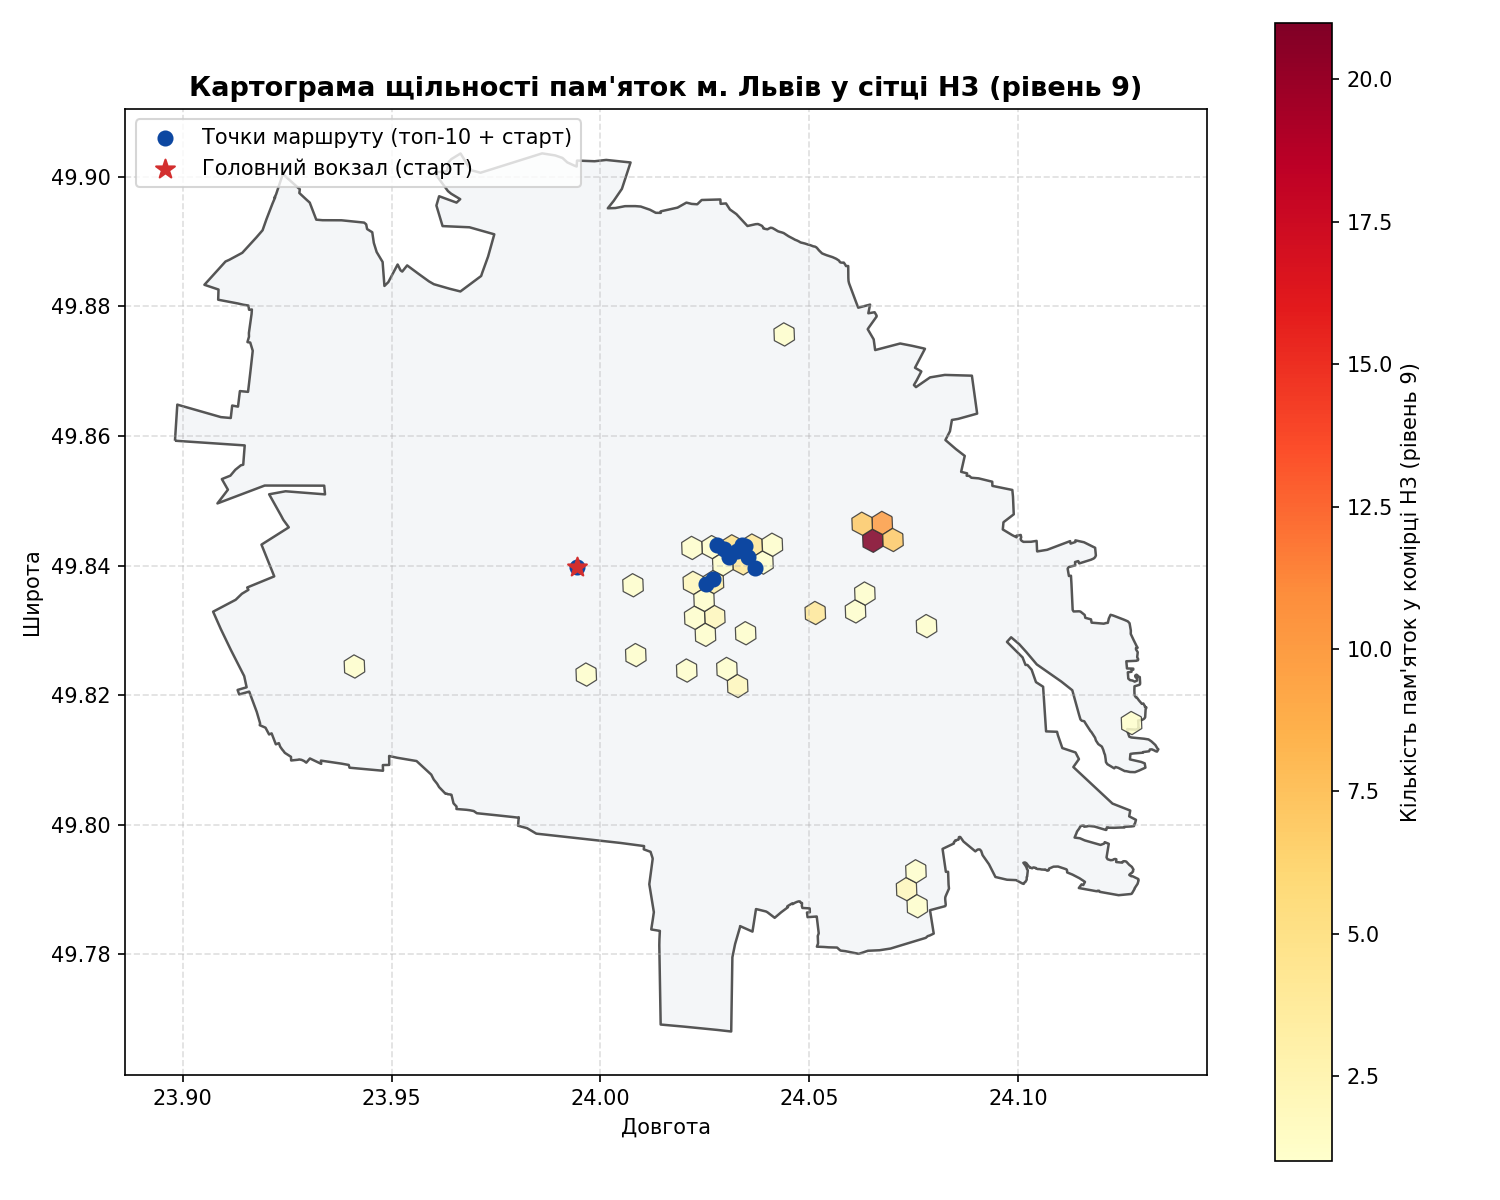

In [27]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

rep_pts = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in rep_pts]
dens = cand['h3'].value_counts().reset_index()
dens.columns = ['h3', 'count']

hexes = gpd.GeoDataFrame(
    dens,
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in dens['h3']],
    crs='EPSG:4326'
)

dens['cum_sum'] = dens['count'].cumsum()
n_half = int((dens['cum_sum'] < len(cand) / 2).sum()) + 1
print('усього комірок H3 з пам\'ятками: %d | половина пам\'яток зосереджена у %d комірках' % (len(dens), n_half))

fig, ax = plt.subplots(figsize=(10, 8))
boundary.plot(ax=ax, facecolor='#f4f6f8', edgecolor='#555555', linewidth=1.2)
hexes.plot(column='count', ax=ax, cmap='YlOrRd', edgecolor='#333333', linewidth=0.6, alpha=0.85, legend=True)
pts10.plot(ax=ax, color='#0d47a1', markersize=45, zorder=5)
ax.set_title('Картограма щільності пам\'яток м. Львів у сітці H3 (рівень 9)')
plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте - місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим - перепроєктуйте обидва шари в метричну систему.

In [28]:
pts10_m = pts10.to_crs(32635)
am_valid = amenities[amenities['name'].notna()][['name', 'amenity', 'geometry']].copy()
am_m = am_valid.to_crs(32635)
am_m['geometry'] = am_m.geometry.representative_point()

joined = gpd.sjoin_nearest(pts10_m, am_m, how='left', distance_col='відстань_м')
joined = joined.loc[~joined.index.duplicated(keep='first')]
joined['відстань_м'] = joined['відстань_м'].round(1)
sjoin_table = joined[['name_left', 'name_right', 'amenity', 'відстань_м']].rename(columns={
    'name_left': 'Точка маршруту',
    'name_right': 'Найближчий заклад',
    'amenity': 'Тип закладу',
    'відстань_м': 'Відстань, м'
}).reset_index(drop=True)
display(sjoin_table)

,Точка маршруту,Найближчий заклад,Тип закладу,"Відстань, м"
0,СТАРТ: Головний вокзал,Експрес,cafe,83.2
1,Палац Потоцьких,Anri-Pharm,pharmacy,85.2
2,Національний музей у Львові,Львівська мануфактура кави,cafe,58.4
3,Королівський арсенал,Cold comfort,cafe,79.4
4,Кам'яниця Корнякта,Щось Цікаве,cafe,27.2
5,Львівський музей історії релігії,Cold comfort,cafe,19.5
6,Львівський Державний Природознавчий Музей,BubbleWaffle,cafe,45.4
7,"Арсенал, Львівський державний історичний музей старовинної зброї",Фреска,cafe,45.5
8,Львівська національна галерея мистецтв,ICoffee,cafe,78.7
9,Музей сакральної барокової скульптури Пінзеля,Франс.уа,cafe,31.6


---
## 9. Маршрут на карті

Лінія маршруту - це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

збережено lr5_маршрут.html


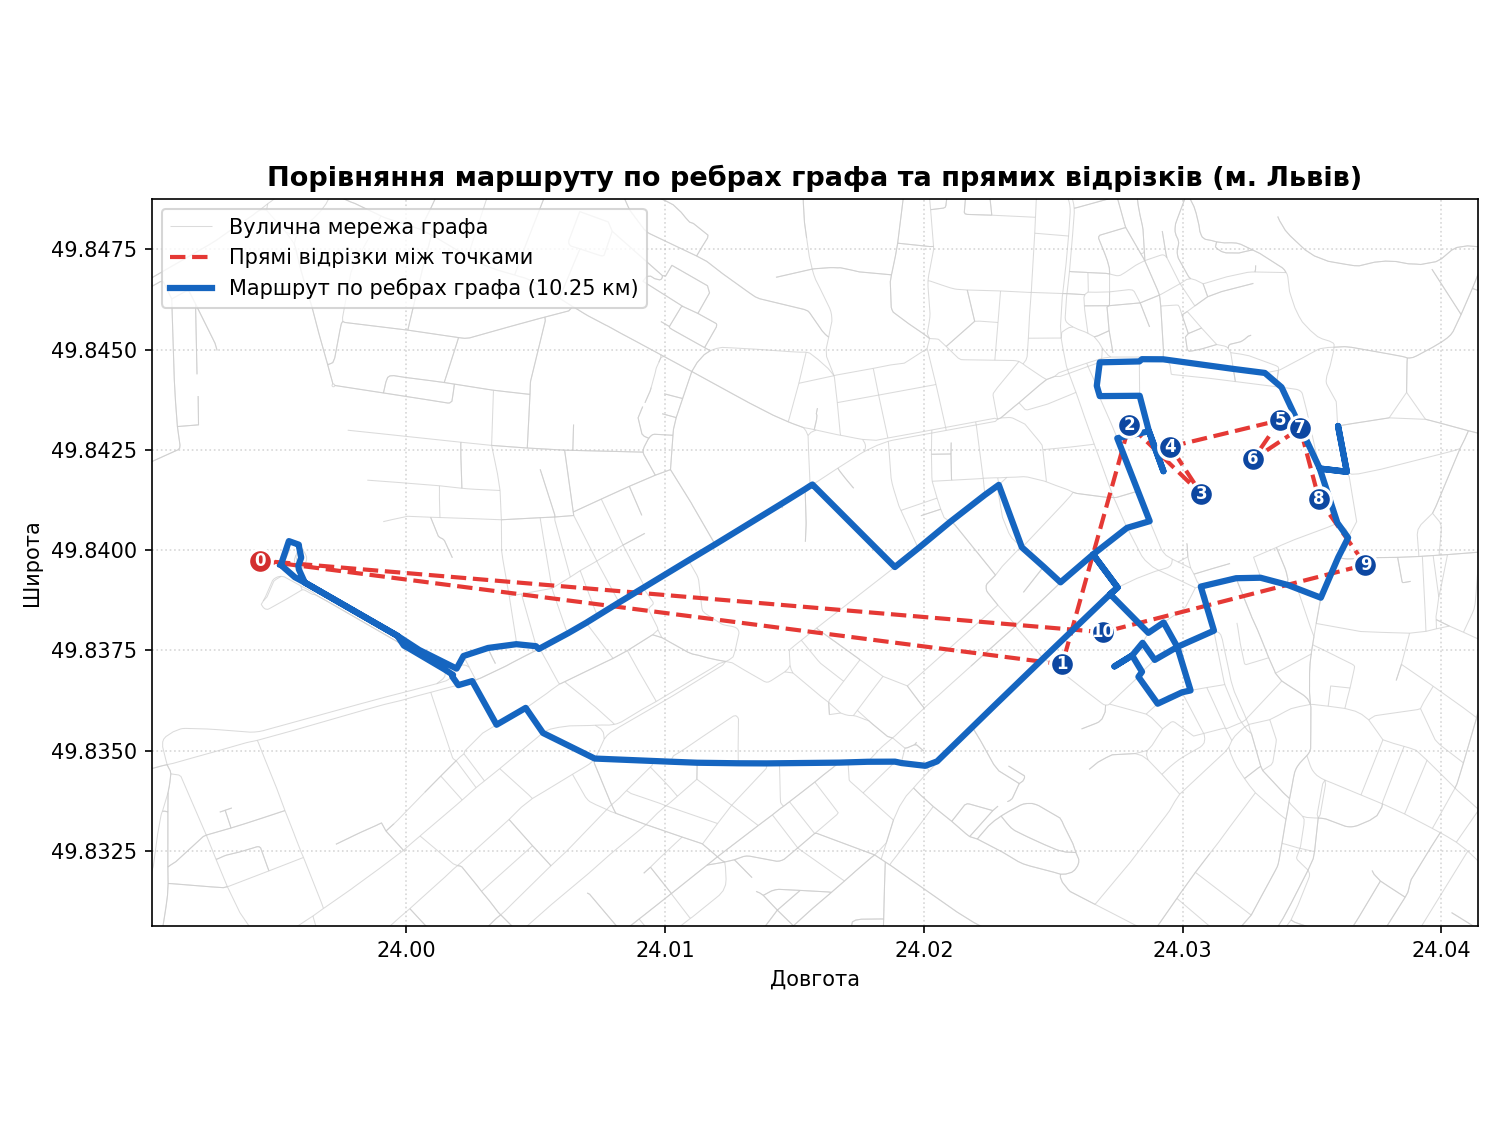

In [29]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

r_coords = route_coords(ex10, ids10)
s_coords = [(float(pts10.geometry.y.iloc[i]), float(pts10.geometry.x.iloc[i])) for i in ex10]

center_lat = float(pts10.geometry.y.mean())
center_lon = float(pts10.geometry.x.mean())
fmap = folium.Map(location=[center_lat, center_lon], zoom_start=14, tiles=BASEMAP)

folium.PolyLine(s_coords, color='#e53935', weight=2.5, dash_array='7, 7',
                tooltip='Прямі відрізки між точками').add_to(fmap)
folium.PolyLine(r_coords, color='#1565c0', weight=4.5,
                tooltip='Маршрут по ребрах графа').add_to(fmap)

for step_idx, pt_idx in enumerate(ex10[:-1]):
    lat_v = float(pts10.geometry.y.iloc[pt_idx])
    lon_v = float(pts10.geometry.x.iloc[pt_idx])
    nm_v = str(pts10['name'].iloc[pt_idx])
    folium.CircleMarker(
        location=[lat_v, lon_v],
        radius=8,
        color='#ffffff',
        weight=2,
        fill=True,
        fill_color='#d32f2f' if step_idx == 0 else '#1565c0',
        fill_opacity=0.95,
        popup=f'{step_idx}. {nm_v}',
        tooltip=f'{step_idx}. {nm_v}'
    ).add_to(fmap)

fmap.save('lr5_маршрут.html')
print('збережено lr5_маршрут.html')

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [30]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.6 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні - що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** - дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання - ні.

In [31]:
REPORT = '''
1. На кроці 2 зі 148 об'єктів шару heritage було відібрано 109 за об'єднанням тегів historic=* або tourism у переліку (museum, attraction, gallery, artwork, viewpoint) - тобто відкинуто 39 комерційних готелів та хостелів (tourism=hotel/hostel/motel). Далі відкинуто ще 14 об'єктів без тега name, після чого залишилось 95 іменованих кандидатів (загалом відкинуто 53 об'єкти). Крім того, у наявному знімку Львова пам'ятки витягнуто з шару будівель, тому всі 95 об'єктів мають тип Polygon, а точкові вузли (пам'ятники, меморіали, оглядові точки) до вибірки не потрапили. Без пояснення цих обмежень віддавати такий фільтр замовнику не можна, бо маршрут омине знакові точкові монументи міста.

2. У рейтинг увійшли 5 сигналів, зведених до спільної відсоткової шкали через rank(pct=True): наявність статті у Вікіпедії чи Wikidata (вага 0.35), кількість іншомовних перекладів назви name:* (вага 0.30), належність до музеїв або галерей tourism=museum/gallery (вага 0.20), наявність історичного тега historic (вага 0.10) та площа полігона будівлі area_m2 (вага 0.05). Найбільшу вагу (сумарно 0.65) надано незалежному зовнішньому визнанню (Вікіпедія/Wikidata) та міжнародній популярності об'єкта серед іноземних туристів (кількість мов), середню - функціональній доступності для огляду всередині (музей/галерея), а площі будівлі надано мінімальну вагу 0.05 лише для розв'язання нічиїх, оскільки великий розмір споруди не означає її культурної цінності.

3. Між десяткою за комплексним критерієм і десяткою за простою площею полігона збіглося 6 об'єктів з 10 (Палац Потоцьких, Національний музей у Львові, Королівський арсенал, Львівський музей історії релігії, Природознавчий музей, Львівська національна галерея мистецтв). Натомість критерій площі вивів на перше місце занедбаний Австрійський форт на околиці (2357.8 м²) та Велику Максиміліанську вежу №1 (1128.0 м²), витіснивши Кам'яницю Корнякта (579.4 м²), Музей Пінзеля та Львівський історичний музей на площі Ринок. Це доводить, що поняття "найкращі" не міститься в сирих даних автоматично - воно визначається тим критерієм і пріоритетами, які закладає аналітик.

4. У малій задачі (10 пам'яток + вокзал) медіанний коефіцієнт обходу становить 1.82, а у великій задачі (30 пам'яток + вокзал) - 1.45, при максимальній асиметрії матриці віддалей 1084 м (для 10 точок) і 1302 м (для 30 точок). Значення 1.82 перевищує типовий діапазон пішохідної мережі (1.2-1.6), а висока асиметрія пояснюється тим, що дорожній граф у наданому знімку Львова містить автомобільні ребра (residential, primary, secondary) з одностороннім рухом у середньовічному центрі та залізничним бар'єром біля Головного вокзалу. Додатково це призвело до злипання сусідніх пам'яток на спільних вузлах графа (10 різних вузлів на 11 точок у малій задачі та 23 різних вузли на 31 точку у великій).

5. У малій задачі жадібний метод найближчого сусіда дав маршрут довжиною 10701 м, що на 4.43% гірше за точний оптимум алгоритму Held-Karp (10247 м, або 10.25 км). Натомість локальна оптимізація 2-opt скоротила маршрут до точного оптимуму 10247 м (похибка 0.00%). На великій задачі (30 пам'яток) найближчий сусід дав 61174 м, а 2-opt всього за 0.024 с зменшив довжину до 50713 м - тобто покращив результат на 17.1% (понад 10.4 км економії шляху). Це підтверджує, що жадібний алгоритм наприкінці обходу змушений робити далекі переходи між пропущеними периферійними точками, тоді як 2-opt ефективно розплутує самоперетини.

6. Точний розв'язок алгоритмом Held-Karp на 30 пам'ятках (n = 31 точка разом зі стартом) неможливий через обсяг необхідної оперативної пам'яті. Розмір таблиці динамічного програмування становить 2^(n-1) * (n-1) = 2^30 * 30 = 32 212 254 720 клітин, що при 8 байтах на одне число типу float64 вимагає 257.7 ГБ (або 240 ГіБ) оперативної пам'яті та близько 9.66 * 10^11 операцій. Така таблиця фізично не вміщується в ОЗП жодного звичайного комп'ютера.

7. Під час перевірки даних OpenStreetMap виявлено чотири класи проблем: (а) дублікати одного й того самого закладу в різних будівлях або полігонах - наприклад, "Львівський музей історії релігії" та "Музей Історії та Релігії" на відстані 26.2 м, два корпуси "Музею Івана Франка" (43.7 м) та "Національний музей" без тега вікі; (б) вкладені або суміжні об'єкти одного комплексу - Палац Потоцьких і Музей мистецтва давньої української книги (58.8 м), Музей Грушевського і Музей Франка (55.8 м); (в) десятки дрібних дерев'яних експонатів скансену "Шевченківський гай" (хати, стайні, каплиці з сіл Либохора, Орявчик, Тухолька тощо), які мають високу деталізацію тегів і масово потрапляють у топ-30, перетворюючи загальноміський маршрут на прогулянку однією парковою зоною; (г) помилкові теги на комерційних чи житлових об'єктах, наприклад філія "Таскомбанк" із тегом historic=heritage або житловий будинок "Сихів" із historic=building. Для очищення маршруту було застосовано просторову фільтрацію близьких пар (у радіусі 60 м залишався лише об'єкт із вищим рейтингом), що усунуло всі 7 колізій у топ-30 і зробило маршрут географічно збалансованим.

Дані © OpenStreetMap contributors, ліцензія ODbL.

Декларація про використання ШІ:
ШІ-помічник використовувався для консультацій щодо синтаксису просторового об'єднання geopandas.sjoin_nearest, побудови сітки шестикутників H3 та оформлення візуалізації маршрутів на карті. Увесь згенерований код було ретельно перевірено вручну: контрольовано обов'язковий перехід у метричну систему координат EPSG:32635 перед обчисленням площ (area_m2), евклідових відстаней і викликом sjoin_nearest, перевірено правильний порядок координат (довгота, широта) для геометрії shapely.Polygon проти (широта, довгота) у карті, а також протестовано структуру маршрутів функцією check_tour.
'''
print(REPORT)

1. На кроці 2 зі 148 об'єктів шару heritage було відібрано 109 за об'єднанням тегів historic=* або tourism у переліку (museum, attraction, gallery, artwork, viewpoint) - тобто відкинуто 39 комерційних готелів та хостелів (tourism=hotel/hostel/motel). Далі відкинуто ще 14 об'єктів без тега name, після чого залишилось 95 іменованих кандидатів (загалом відкинуто 53 об'єкти). Крім того, у наявному знімку Львова пам'ятки витягнуто з шару будівель, тому всі 95 об'єктів мають тип Polygon, а точкові вузли (пам'ятники, меморіали, оглядові точки) до вибірки не потрапили. Без пояснення цих обмежень віддавати такий фільтр замовнику не можна, бо маршрут омине знакові точкові монументи міста.

2. У рейтинг увійшли 5 сигналів, зведених до спільної відсоткової шкали через rank(pct=True): наявність статті у Вікіпедії чи Wikidata (вага 0.35), кількість іншомовних перекладів назви name:* (вага 0.30), належність до музеїв або галерей tourism=museum/gallery (вага 0.20), наявність історичного тега historic 